In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from sklearn.linear_model import LinearRegression, SGDRegressor

from sklearn.metrics import r2_score

from sklearn.pipeline import Pipeline

In [21]:
X = 6 * np.random.rand(200,1) - 3
y = 0.8*X**(2) + 0.9*X + 2 + np.random.randn(200,1)

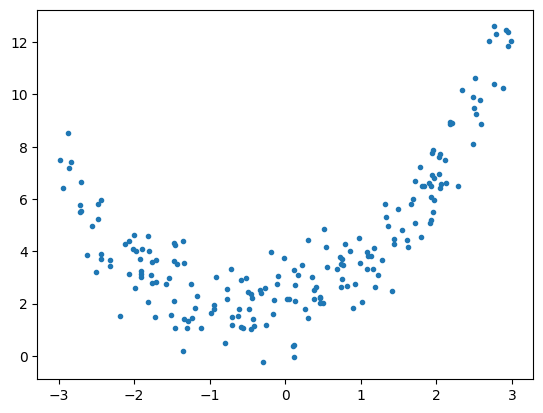

In [22]:
plt.plot(X,y ,'.')

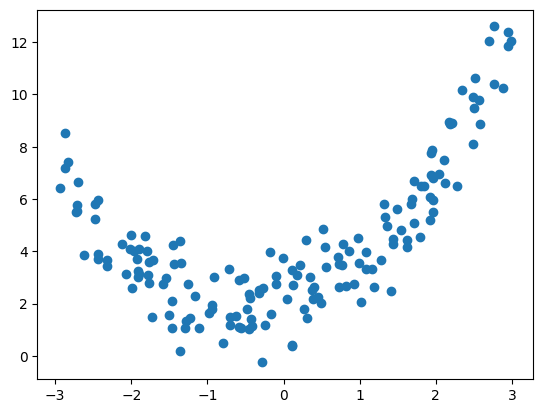

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 2)
plt.plot(X_train,y_train,'o')

In [24]:
lr = LinearRegression()
lr.fit(X_train,y_train)

LinearRegression()

In [25]:
y_pred = lr.predict(X_test)
y_pred

array([[3.64598981],
       [3.15011555],
       [6.07370818],
       [3.78412636],
       [4.70821372],
       [4.89787085],
       [2.15424599],
       [2.42580138],
       [3.64958871],
       [5.25011218],
       [6.06115751],
       [5.08027071],
       [6.07608334],
       [2.8321988 ],
       [2.74603278],
       [4.4125217 ],
       [2.10753803],
       [4.42321192],
       [6.82574348],
       [5.97495105],
       [4.18475452],
       [4.95760172],
       [2.52773265],
       [4.70978363],
       [5.29228659],
       [4.32530539],
       [4.95871035],
       [3.04135711],
       [3.03572111],
       [5.94837558],
       [5.37232151],
       [3.27810075],
       [6.70808113],
       [1.73985017],
       [3.88987541],
       [5.32227866],
       [5.85107274],
       [6.08125057],
       [5.9555939 ],
       [6.4832606 ]])

In [27]:
r2_score(y_test,y_pred)

0.31119570687392584

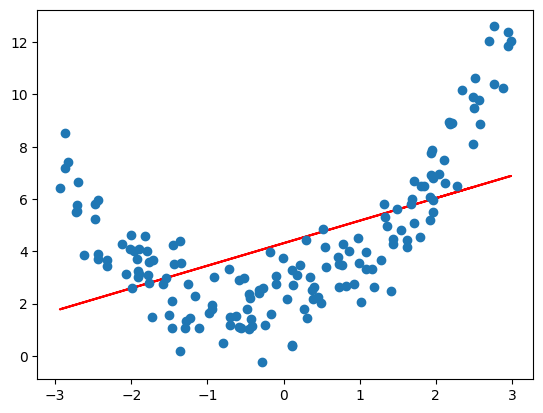

In [32]:
plt.plot(X_train,lr.predict(X_train),color='red')
plt.plot(X_train,y_train,'o')

In [37]:
pf = PolynomialFeatures(degree=2, include_bias=True)
X_train_poly = pf.fit_transform(X_train)
X_test_poly = pf.transform(X_test)

X_train_poly

array([[ 1.00000000e+00,  2.48642824e+00,  6.18232541e+00],
       [ 1.00000000e+00, -5.81942464e-01,  3.38657031e-01],
       [ 1.00000000e+00, -1.11119611e+00,  1.23475680e+00],
       [ 1.00000000e+00,  1.79548124e+00,  3.22375288e+00],
       [ 1.00000000e+00,  4.94908111e-01,  2.44934038e-01],
       [ 1.00000000e+00,  1.43550116e+00,  2.06066357e+00],
       [ 1.00000000e+00,  1.28000632e+00,  1.63841618e+00],
       [ 1.00000000e+00, -2.44302168e+00,  5.96835491e+00],
       [ 1.00000000e+00, -1.16462021e+00,  1.35634023e+00],
       [ 1.00000000e+00, -5.57873234e-01,  3.11222545e-01],
       [ 1.00000000e+00,  7.69771481e-01,  5.92548133e-01],
       [ 1.00000000e+00,  1.92647521e+00,  3.71130672e+00],
       [ 1.00000000e+00,  5.15614392e-01,  2.65858201e-01],
       [ 1.00000000e+00,  1.43438517e+00,  2.05746081e+00],
       [ 1.00000000e+00,  1.09137081e-01,  1.19109023e-02],
       [ 1.00000000e+00, -4.54946269e-01,  2.06976108e-01],
       [ 1.00000000e+00,  9.19964717e-01

In [39]:
lr2 = LinearRegression()
lr2.fit(X_train_poly, y_train)

LinearRegression()

In [40]:
y_pred_2 = lr2.predict(X_test_poly)
r2_score(y_test, y_pred_2)

0.883410078076402

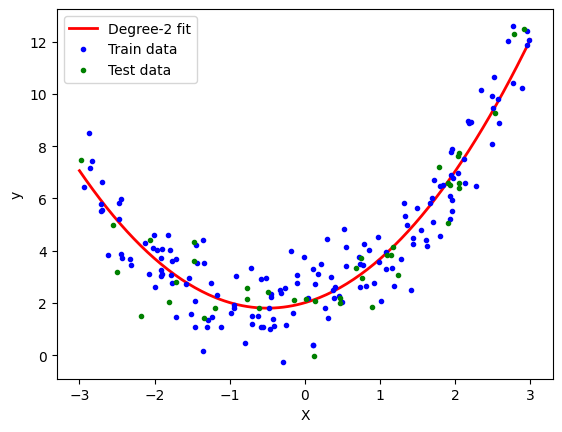

In [47]:
X_new = np.linspace(-3, 3, 200).reshape(-1, 1)   # evenly spaced, sorted inputs
X_new_poly = pf.transform(X_new)               # same feature expansion as training
y_new = lr2.predict(X_new_poly)

plt.plot(X_new, y_new, 'r-', linewidth=2, label='Degree-2 fit')
plt.plot(X_train, y_train, 'b.', label='Train data')
plt.plot(X_test, y_test, 'g.', label='Test data')
plt.xlabel('X'); plt.ylabel('y'); plt.legend()
plt.show()